# Assignment 4 - Konnect Fibernet Churn Analysis


## Part A - Data cleaning (Q1-Q8)

### Q1. Load the file, report its shape, and rename every column to snake_case

In [67]:
# Q1
from pathlib import Path
import pandas as pd
import numpy as np
import re
import warnings
from dateutil import parser
from scipy import stats
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
SNAPSHOT = pd.Timestamp('2026-10-31')
DATA_PATH = Path('konnect_fibernet_churn_raw.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('/mnt/data/konnect_fibernet_churn_raw.csv')

# keep_default_na=False is deliberate: the literal complaint label "None" is valid.
raw = pd.read_csv(DATA_PATH, low_memory=False, keep_default_na=False)

def snake_case(name):
    name = str(name).strip()
    name = re.sub(r'([a-z0-9])([A-Z])', r'\1_\2', name)
    name = re.sub(r'([A-Z]+)([A-Z][a-z])', r'\1_\2', name)
    name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_').lower()
    return re.sub(r'_+', '_', name)

df = raw.copy()
df.columns = [snake_case(c) for c in df.columns]
print('Original shape:', raw.shape)
print('Shape after column rename:', df.shape)
print('Renamed columns:', df.columns.tolist())

Original shape: (6180, 25)
Shape after column rename: (6180, 25)
Renamed columns: ['customer_id', 'signup_date', 'city', 'gender', 'age', 'senior_citizen', 'plan_type', 'contract', 'payment_method', 'tenure_months', 'monthly_charges', 'total_charges', 'ott_bundle', 'router_type', 'avg_download_speed_mbps', 'data_usage_gb', 'outages_6m', 'support_tickets_6m', 'avg_resolution_hrs', 'csat', 'last_complaint_category', 'pilot_group', 'speed_test_jun', 'speed_test_oct', 'churn']


**Interpretation:** The supplied extract has 6,180 rows and 25 columns. The column names are normalised to lowercase snake_case, including `TotalCharges` → `total_charges` and `SeniorCitizen` → `senior_citizen`.

### Q2. Strip whitespace and remove duplicate customers

In [68]:
# Q2
for col in df.select_dtypes(include='object'):
    df[col] = df[col].str.strip()
rows_before = len(df)
duplicate_mask = df.duplicated(subset='customer_id', keep='first')
duplicate_count = int(duplicate_mask.sum())
df = df.loc[~duplicate_mask].copy()
print('Duplicate customer rows removed:', duplicate_count)
print('Rows remaining:', len(df))
print('Unique customer IDs remaining:', df.customer_id.nunique())

Duplicate customer rows removed: 180
Rows remaining: 6000
Unique customer IDs remaining: 6000


**Interpretation:** 180 repeated customer-ID rows are removed, leaving 6,000 unique customers. Whitespace is stripped before checking duplicates so cosmetic spacing cannot hide a repeat.

### Q3. Convert disguised missing values to NaN and print missing counts

In [69]:
# Q3
MISSING_TOKENS = {'na', 'null', '?', 'n/a', '-', 'missing', ''}
for col in df.select_dtypes(include='object'):
    df[col] = df[col].apply(
        lambda value: np.nan
        if isinstance(value, str) and value.strip().lower() in MISSING_TOKENS
        else value
    )
missing_q3 = df.isna().sum().sort_values(ascending=False)
display(missing_q3.rename('missing_count').to_frame())
print('Total missing cells:', int(missing_q3.sum()))
print('Note: literal "None" is not in the missing-token set; it means no complaint.')

,missing_count
speed_test_jun,5820
speed_test_oct,5820
csat,397
avg_resolution_hrs,324
age,222
data_usage_gb,221
avg_download_speed_mbps,182
total_charges,181
payment_method,175
last_complaint_category,94


Total missing cells: 13436
Note: literal "None" is not in the missing-token set; it means no complaint.


**Interpretation:** All specified placeholders and blank strings become true missing values. The complaint category `None` is preserved as a legitimate no-complaint category, not treated as missing.

### Q4. Standardise categorical values and encode OTT and churn

In [70]:
# Q4
def norm_text(value):
    return value.strip().lower() if isinstance(value, str) else value

city_map = {
    'bombay': 'Mumbai', 'mumbai': 'Mumbai',
    'poona': 'Pune', 'pune': 'Pune',
    'nasik': 'Nashik', 'nashik': 'Nashik',
    'nagpur': 'Nagpur',
    'aurangabad': 'Aurangabad', 'chh. sambhajinagar': 'Aurangabad'
}
df['city'] = df['city'].map(norm_text).map(city_map)
df['gender'] = df['gender'].map(norm_text).map({
    'm': 'Male', 'male': 'Male', 'f': 'Female', 'fem': 'Female', 'female': 'Female'
})
df['contract'] = df['contract'].map(norm_text).map({
    'monthly': 'Monthly', 'm2m': 'Monthly', 'month-to-month': 'Monthly',
    'quarterly': 'Quarterly', '3 months': 'Quarterly',
    'annual': 'Annual', 'yearly': 'Annual', '12 months': 'Annual'
})
df['plan_type'] = df['plan_type'].map(norm_text).map({
    'basic': 'Basic 50 Mbps', 'basic-50': 'Basic 50 Mbps', 'basic 50 mbps': 'Basic 50 Mbps',
    'standard': 'Standard 100 Mbps', 'std 100': 'Standard 100 Mbps', 'standard 100 mbps': 'Standard 100 Mbps',
    'premium': 'Premium 300 Mbps', 'premium-300': 'Premium 300 Mbps', 'premium 300 mbps': 'Premium 300 Mbps',
    'ultra': 'Ultra 1 Gbps', 'ultra 1000': 'Ultra 1 Gbps', 'ultra 1 gbps': 'Ultra 1 Gbps'
})
df['payment_method'] = df['payment_method'].map(norm_text).map({
    'upi autopay': 'UPI AutoPay', 'credit card': 'Credit Card',
    'net banking': 'Net Banking', 'cash/cheque': 'Cash/Cheque'
})
df['router_type'] = df['router_type'].map(norm_text).map({
    'old (ont-v1)': 'Old (ONT-v1)', 'new (ont-v3)': 'New (ONT-v3)'
})
df['pilot_group'] = df['pilot_group'].map(norm_text).map({'yes': 'Yes', 'no': 'No'})

def to_binary(value):
    key = norm_text(value)
    return {'yes': 1, 'y': 1, 'true': 1, '1': 1,
            'no': 0, 'n': 0, 'false': 0, '0': 0}.get(key, np.nan)

df['ott_bundle'] = df['ott_bundle'].map(to_binary)
df['churn'] = df['churn'].map(to_binary)
df['last_complaint_category'] = df['last_complaint_category'].map(norm_text).map({
    'slow speed': 'Slow speed', 'frequent disconnection': 'Frequent disconnection',
    'billing dispute': 'Billing dispute', 'installation delay': 'Installation delay',
    'router fault': 'Router fault', 'none': 'None'
})

for col in ['city', 'gender', 'contract', 'plan_type', 'payment_method', 'router_type', 'last_complaint_category', 'pilot_group']:
    print(f'{col}:', sorted(df[col].dropna().unique().tolist()))
print('ott_bundle:', sorted(df.ott_bundle.dropna().unique().tolist()))
print('churn:', sorted(df.churn.dropna().unique().tolist()))

city: ['Aurangabad', 'Mumbai', 'Nagpur', 'Nashik', 'Pune']
gender: ['Female', 'Male']
contract: ['Annual', 'Monthly', 'Quarterly']
plan_type: ['Basic 50 Mbps', 'Premium 300 Mbps', 'Standard 100 Mbps', 'Ultra 1 Gbps']
payment_method: ['Cash/Cheque', 'Credit Card', 'Net Banking', 'UPI AutoPay']
router_type: ['New (ONT-v3)', 'Old (ONT-v1)']
last_complaint_category: ['Billing dispute', 'Frequent disconnection', 'Installation delay', 'None', 'Router fault', 'Slow speed']
pilot_group: ['No', 'Yes']
ott_bundle: [0, 1]
churn: [0, 1]


**Interpretation:** City aliases are unified (Bombay→Mumbai, Poona→Pune, Nasik→Nashik, and Chh. Sambhajinagar→Aurangabad). Gender, contract, plan and payment labels are canonicalised; OTT and churn are encoded as 1/0.

### Q5. Convert currency and CSAT to numeric values

In [71]:
# Q5
def money_to_number(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    text = text.replace('₹', '').replace('Rs.', '').replace('Rs', '')
    text = text.replace(',', '').replace(' ', '')
    return pd.to_numeric(text, errors='coerce')

for col in ['monthly_charges', 'total_charges']:
    df[col] = df[col].map(money_to_number)
# Convert the remaining measured numeric fields after the missing markers were standardised.
for col in ['age', 'senior_citizen', 'tenure_months', 'avg_download_speed_mbps', 'data_usage_gb',
            'outages_6m', 'support_tickets_6m', 'avg_resolution_hrs', 'speed_test_jun', 'speed_test_oct']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

def parse_csat(value):
    if pd.isna(value):
        return np.nan
    match = re.fullmatch(r'\s*([1-5])\s*(?:/\s*5|stars?)?\s*', str(value), flags=re.I)
    return int(match.group(1)) if match else np.nan

df['csat'] = df['csat'].map(parse_csat).astype('Int64')
print(df[['monthly_charges', 'total_charges', 'csat']].dtypes)
print('CSAT categories:', sorted(df.csat.dropna().unique().tolist()))
print('Monthly charges summary:')
print(df.monthly_charges.describe().round(2))
print('Total charges summary:')
print(df.total_charges.describe().round(2))

monthly_charges    float64
total_charges      float64
csat                 Int64
dtype: object
CSAT categories: [1, 2, 3, 4, 5]
Monthly charges summary:
count    6000.00
mean      971.01
std       385.16
min       476.11
25%       701.22
50%       832.60
75%      1155.69
max      2015.30
Name: monthly_charges, dtype: float64
Total charges summary:
count      5819.00
mean      23857.79
std       18947.86
min         482.34
25%       10268.28
50%       19684.00
75%       31650.42
max      137489.16
Name: total_charges, dtype: float64


**Interpretation:** Currency symbols, `Rs.` prefixes, commas and spaces are stripped before numeric conversion. CSAT strings such as `4/5` and `4 stars` become integer scores from 1 to 5; malformed or out-of-range entries remain missing.

### Q6. Parse the mixed signup-date formats and explain the genuine ambiguity

In [72]:
# Q6
ambiguous_dates = []
def parse_signup_date(value):
    if pd.isna(value):
        return pd.NaT
    text = str(value).strip()
    # ISO-style YYYY-MM-DD (or YYYY/MM/DD) is year-first.
    if re.match(r'^\d{4}[-/.]\d{1,2}[-/.]\d{1,2}$', text):
        return pd.to_datetime(text, yearfirst=True, errors='coerce')
    # Numeric day/month/year or month/day/year.
    match = re.match(r'^(\d{1,2})[/.\-](\d{1,2})[/.\-](\d{4})$', text)
    if match:
        first, second, _ = map(int, match.groups())
        if first <= 12 and second <= 12:
            ambiguous_dates.append(text)
            dayfirst = True  # stated assumption for this Indian customer extract
        elif first > 12:
            dayfirst = True
        else:
            dayfirst = False
        return pd.to_datetime(text, dayfirst=dayfirst, errors='coerce')
    # Month-name formats (e.g. 09-Jun-2026, June 09, 2026).
    try:
        return pd.Timestamp(parser.parse(text, dayfirst=True, fuzzy=False))
    except Exception:
        return pd.NaT

df['signup_date'] = df['signup_date'].map(parse_signup_date)
future_signup_count = int((df.signup_date > SNAPSHOT).sum())
# A snapshot cannot include future activations; retain the customer but set the invalid date to NaT.
df.loc[df.signup_date > SNAPSHOT, 'signup_date'] = pd.NaT
print('Ambiguous numeric dates (both first fields <= 12):', len(ambiguous_dates))
print('Future-dated signup entries set to NaT:', future_signup_count)
print('Unparsed / invalid signup dates:', int(df.signup_date.isna().sum()))
print('Parsed date range:', df.signup_date.min(), 'to', df.signup_date.max())
print('Assumption: ambiguous numeric dates are interpreted as DD/MM/YYYY (day-first).')

Ambiguous numeric dates (both first fields <= 12): 726
Future-dated signup entries set to NaT: 5
Unparsed / invalid signup dates: 5
Parsed date range: 2020-11-06 00:00:00 to 2026-10-09 00:00:00
Assumption: ambiguous numeric dates are interpreted as DD/MM/YYYY (day-first).


**Interpretation:** ISO and month-name dates are parsed directly; non-ambiguous numeric dates are resolved from the component greater than 12. The genuinely ambiguous format is numeric `DD/MM/YYYY` versus `MM/DD/YYYY` when both fields are 12 or less. I assume day-first, consistent with an Indian source. Five dates after the 31-Oct-2026 snapshot are set to missing rather than retained as future activations.

### Q7. Identify impossible values in age, tenure and resolution hours

In [73]:
# Q7
for col in ['age', 'tenure_months', 'avg_resolution_hrs']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
# Age <18 or >100 is treated as implausible for a named household subscriber.
# Earliest signup is Nov-2020, so max possible tenure at the Oct-2026 snapshot is 71 months.
age_invalid = (df.age < 18) | (df.age > 100)
tenure_invalid = (df.tenure_months < 0) | (df.tenure_months > 71)
resolution_invalid = df.avg_resolution_hrs < 0
print('Impossible age values (<18 or >100):', int(age_invalid.sum()))
print('Impossible tenure values (<0 or >71 months):', int(tenure_invalid.sum()))
print('Impossible negative resolution-hour values:', int(resolution_invalid.sum()))
print('Largest observed raw tenure:', df.tenure_months.max())
print('Largest observed resolution hours before cleaning:', df.avg_resolution_hrs.max())
df.loc[age_invalid, 'age'] = np.nan
df.loc[tenure_invalid, 'tenure_months'] = np.nan
df.loc[resolution_invalid, 'avg_resolution_hrs'] = np.nan

Impossible age values (<18 or >100): 5
Impossible tenure values (<0 or >71 months): 2
Impossible negative resolution-hour values: 1
Largest observed raw tenure: 840
Largest observed resolution hours before cleaning: 1200.0


**Interpretation:** Five ages outside the assumed 18–100 subscriber range, two tenure values outside the possible 0–71-month observation window (including an 840-month entry), and one negative resolution duration are set to NaN. The 1,200-hour maximum is extreme but not mathematically impossible, so it is retained and flagged as an outlier in Q12.

### Q8. Set the missing-value policy and save the cleaned dataset

In [74]:
# Q8
# Do not globally impute: missingness in charges, service measures and CSAT may be informative.
# Tests use complete-case samples for only the variables involved in each question.
# Pilot speed tests are structurally not applicable for non-pilot customers and are never imputed.
for col in ['speed_test_jun', 'speed_test_oct']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

missing_policy = pd.DataFrame([
    ('customer_id', 'Keep; no missing IDs after 180 duplicate rows are removed.'),
    ('signup_date', 'Leave NaT for invalid or future-dated values; do not guess.'),
    ('city', 'Keep valid canonical city; unmapped/missing values remain NaN (no mode imputation).'),
    ('gender', 'Keep valid Male/Female labels; unmapped/missing values remain NaN.'),
    ('age', 'Leave missing/implausible age as NaN; do not median-impute demographic values.'),
    ('senior_citizen', 'Keep the valid 0/1 flag; invalid/missing values would remain NaN.'),
    ('plan_type', 'Keep valid plan label; unmapped/missing values remain NaN.'),
    ('contract', 'Keep valid contract label; unmapped/missing values remain NaN.'),
    ('payment_method', 'Leave NaN; mode-imputation could bias payment-method/churn association.'),
    ('tenure_months', 'Leave missing/impossible tenure as NaN; do not fabricate customer tenure.'),
    ('monthly_charges', 'Leave parsing failures/missing charges as NaN; do not fabricate revenue.'),
    ('total_charges', 'Leave missing cumulative billing as NaN; it is not safely inferred for all customers.'),
    ('ott_bundle', 'Keep valid 0/1 values; invalid/missing values remain NaN.'),
    ('router_type', 'Keep valid router label; unmapped/missing values remain NaN.'),
    ('avg_download_speed_mbps', 'Leave missing speed readings as NaN; analyse observed measurements only.'),
    ('data_usage_gb', 'Leave missing usage readings as NaN; no median imputation.'),
    ('outages_6m', 'Keep valid observed outage counts; missing values remain NaN.'),
    ('support_tickets_6m', 'Keep valid observed ticket counts; missing values remain NaN.'),
    ('avg_resolution_hrs', 'Leave missing/invalid resolution durations as NaN; retain genuine extreme values for outlier review.'),
    ('csat', 'Leave missing/invalid satisfaction ratings as NaN; do not replace an opinion score with a mode.'),
    ('last_complaint_category', 'Leave missing category as NaN; literal None is a valid no-complaint category.'),
    ('pilot_group', 'Keep valid Yes/No label; unmapped/missing values remain NaN.'),
    ('speed_test_jun', 'Never impute: measured only for pilot customers; non-pilot missingness is structural.'),
    ('speed_test_oct', 'Never impute: paired post-upgrade measurement exists only for pilot customers.'),
    ('churn', 'Keep valid 0/1 outcome; invalid/missing values remain NaN.')
], columns=['column', 'missing-value decision and reason'])
display(missing_policy)
missing_after_cleaning = df.isna().sum().sort_values(ascending=False)
display(missing_after_cleaning.rename('missing_count').to_frame())
print('Pilot customers:', int((df.pilot_group == 'Yes').sum()))
print('Pilot customers with both speed tests:', int(df.loc[df.pilot_group == 'Yes', ['speed_test_jun','speed_test_oct']].notna().all(axis=1).sum()))
print('Final shape:', df.shape)
OUTPUT_CSV = Path('konnect_churn_clean.csv')
df.to_csv(OUTPUT_CSV, index=False)
print('Saved:', OUTPUT_CSV.resolve())

,column,missing-value decision and reason
0,customer_id,Keep; no missing IDs after 180 duplicate rows ...
1,signup_date,Leave NaT for invalid or future-dated values; ...
2,city,Keep valid canonical city; unmapped/missing va...
3,gender,Keep valid Male/Female labels; unmapped/missin...
4,age,Leave missing/implausible age as NaN; do not m...
5,senior_citizen,Keep the valid 0/1 flag; invalid/missing value...
6,plan_type,Keep valid plan label; unmapped/missing values...
7,contract,Keep valid contract label; unmapped/missing va...
8,payment_method,Leave NaN; mode-imputation could bias payment-...
9,tenure_months,Leave missing/impossible tenure as NaN; do not...


,missing_count
speed_test_jun,5820
speed_test_oct,5820
csat,397
avg_resolution_hrs,325
age,227
data_usage_gb,221
avg_download_speed_mbps,182
total_charges,181
payment_method,175
last_complaint_category,94


Pilot customers: 180
Pilot customers with both speed tests: 180
Final shape: (6000, 25)
Saved: /content/konnect_churn_clean.csv


**Interpretation:** The cleaned file keeps all 6,000 unique customers. Missing observations are left as NaN and excluded only where the relevant analysis requires them; no median/mode imputation is applied to inferential variables. The June/October speed fields remain missing for non-pilot customers because they were never measured for them.

## Part B - Exploratory data analysis (Q9-Q14)

### Q9. Calculate the overall churn rate

In [75]:
# Q9
churn_observed = df.churn.dropna()
overall_churn = churn_observed.mean()
print(f'Customers analysed: {len(churn_observed):,}')
print(f'Churners: {int(churn_observed.sum()):,}')
print(f'Overall churn rate: {overall_churn:.2%}')

Customers analysed: 6,000
Churners: 2,004
Overall churn rate: 33.40%


**Interpretation:** 2,004 of 6,000 customers churned, giving an overall churn rate of **33.40%**, which is above the 30% industry reference.

### Q10. Churn rate by contract, plan, payment method, OTT, router, city and gender


Churn by contract:


,contract,customers,churners,churn_rate
0,Monthly,3053,1439,47.13%
1,Quarterly,1350,340,25.19%
2,Annual,1597,225,14.09%


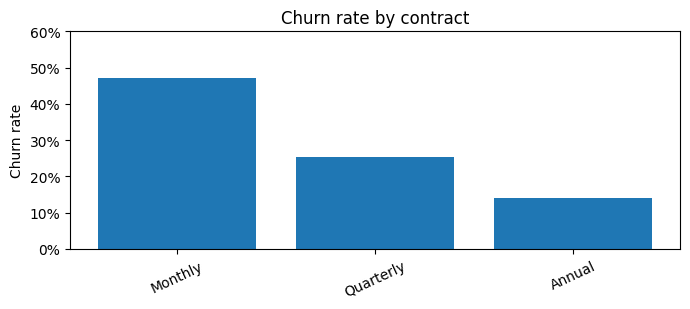


Churn by plan_type:


,plan_type,customers,churners,churn_rate
0,Ultra 1 Gbps,648,305,47.07%
1,Premium 300 Mbps,1302,488,37.48%
2,Standard 100 Mbps,2238,711,31.77%
3,Basic 50 Mbps,1812,500,27.59%


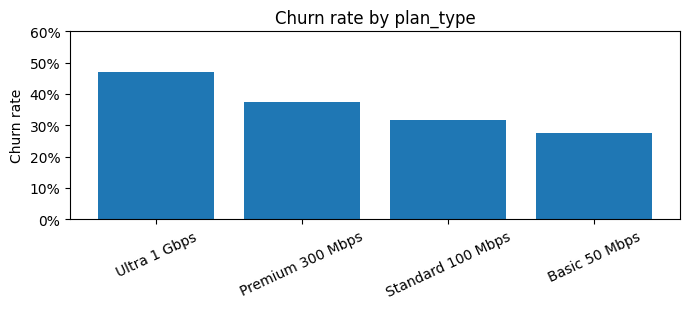


Churn by payment_method:


,payment_method,customers,churners,churn_rate
0,Cash/Cheque,1011,431,42.63%
1,Credit Card,1269,432,34.04%
2,Net Banking,1173,359,30.61%
3,UPI AutoPay,2372,724,30.52%


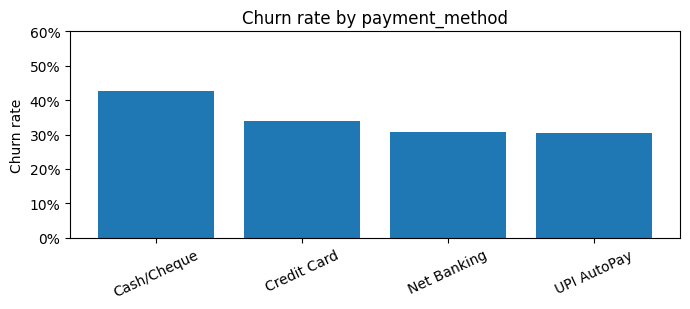


Churn by ott_bundle:


,ott_bundle,customers,churners,churn_rate
0,0,3450,1284,37.22%
1,1,2550,720,28.24%


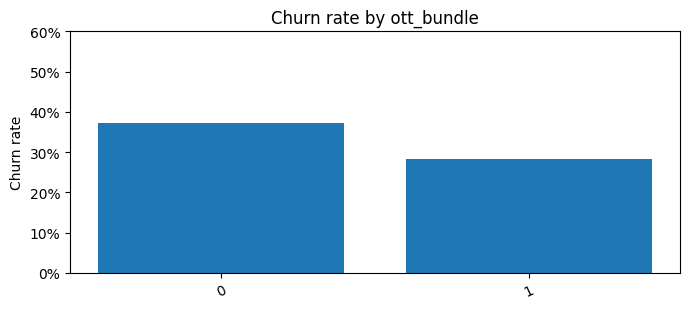


Churn by router_type:


,router_type,customers,churners,churn_rate
0,Old (ONT-v1),2175,939,43.17%
1,New (ONT-v3),3825,1065,27.84%


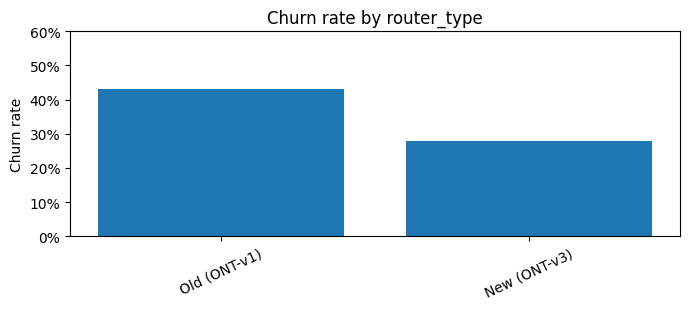


Churn by city:


,city,customers,churners,churn_rate
0,Nagpur,890,320,35.96%
1,Nashik,943,321,34.04%
2,Pune,1743,593,34.02%
3,Mumbai,1668,531,31.83%
4,Aurangabad,756,239,31.61%


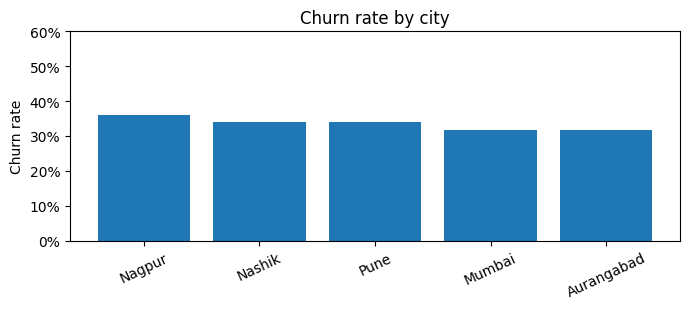


Churn by gender:


,gender,customers,churners,churn_rate
0,Female,2624,878,33.46%
1,Male,3376,1126,33.35%


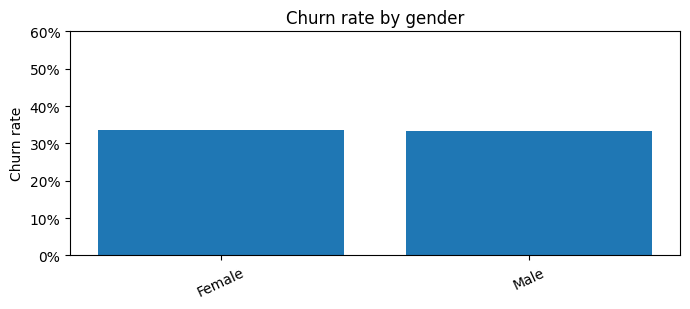


Largest descriptive gaps: contract (Monthly 47.13% vs Annual 14.09%),
plan (Ultra 47.07% vs Basic 27.59%), router (Old 43.17% vs New 27.84%).
Payment method, OTT and city patterns are also visible; missing payment methods are excluded from that breakdown.


In [76]:
# Q10
factors = ['contract', 'plan_type', 'payment_method', 'ott_bundle', 'router_type', 'city', 'gender']
churn_tables = {}
for col in factors:
    table = (df.groupby(col, dropna=True).churn
             .agg(customers='count', churners='sum', churn_rate='mean')
             .sort_values('churn_rate', ascending=False).reset_index())
    churn_tables[col] = table
    print(f'\nChurn by {col}:')
    display(table.style.format({'churn_rate': '{:.2%}'}))
    fig, ax = plt.subplots(figsize=(7, 3.2))
    labels = table[col].astype(str).tolist()
    ax.bar(labels, table['churn_rate'])
    ax.set_title(f'Churn rate by {col}')
    ax.set_ylabel('Churn rate')
    ax.set_ylim(0, 0.60)
    ax.tick_params(axis='x', rotation=25)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    plt.tight_layout(); plt.show()
print('\nLargest descriptive gaps: contract (Monthly 47.13% vs Annual 14.09%),')
print('plan (Ultra 47.07% vs Basic 27.59%), router (Old 43.17% vs New 27.84%).')
print('Payment method, OTT and city patterns are also visible; missing payment methods are excluded from that breakdown.')

**Interpretation:** The largest descriptive gaps are by **contract**, **plan**, and **router type**. Monthly-contract customers churn at 47.13% versus 14.09% for annual; Ultra customers at 47.07% versus 27.59% for Basic; old routers at 43.17% versus 27.84% for new routers. These are associations, not causal effects.

### Q11. Compare churners and stayers using means and medians

In [77]:
# Q11
profile_cols = ['tenure_months', 'monthly_charges', 'outages_6m', 'support_tickets_6m', 'avg_resolution_hrs', 'csat']
profile = df.groupby('churn')[profile_cols].agg(['mean', 'median']).T
profile.columns = ['Stayers (churn=0)', 'Churners (churn=1)']
display(profile.round(2))

Stayers (churn=0) Churners (churn=1)
tenure_months      mean           28.326909           18.73989
                   median              27.0               17.0
monthly_charges    mean          942.347788        1028.159441
                   median           823.735            918.455
outages_6m         mean            1.864615           2.756487
                   median               2.0                3.0
support_tickets_6m mean            1.557057             2.2001
                   median               1.0                2.0
avg_resolution_hrs mean           19.981234          20.981818
                   median              17.4               18.5
csat               mean            3.833468           3.002114
                   median               4.0                3.0

**Interpretation:** Churners have shorter tenure (mean 18.74 vs 28.33 months; median 17 vs 27), lower CSAT (3.00 vs 3.83), more outages (2.76 vs 1.86) and more tickets (2.20 vs 1.56). Their monthly charges are actually higher (₹1,028 vs ₹942), so they are not simply low-value customers. Resolution-time means differ by only about one hour.

### Q12. Plot histograms and box plots; calculate skewness and 1.5×IQR outliers

avg_resolution_hrs: n=5675, skew=36.684, Q1=11.80, Q3=25.60, IQR=13.80, fences=(-8.90, 46.30), outliers=162


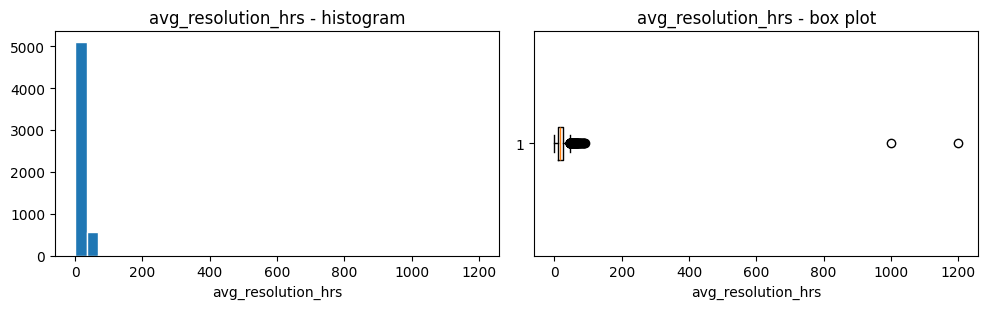

support_tickets_6m: n=6000, skew=1.190, Q1=1.00, Q3=3.00, IQR=2.00, fences=(-2.00, 6.00), outliers=84


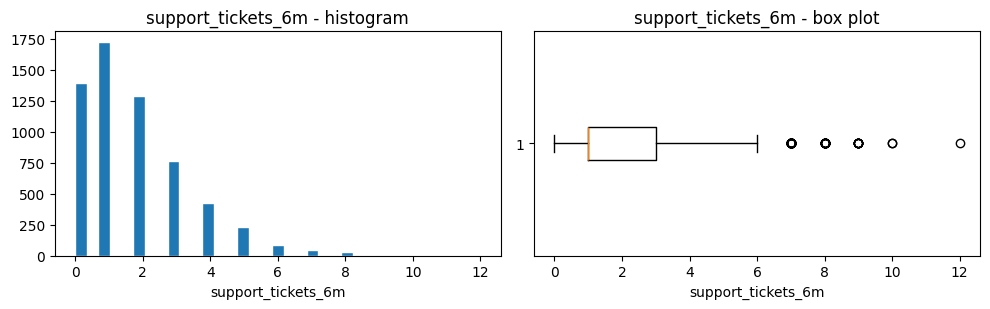

data_usage_gb: n=5779, skew=2.815, Q1=97.45, Q3=261.50, IQR=164.05, fences=(-148.62, 507.58), outliers=426


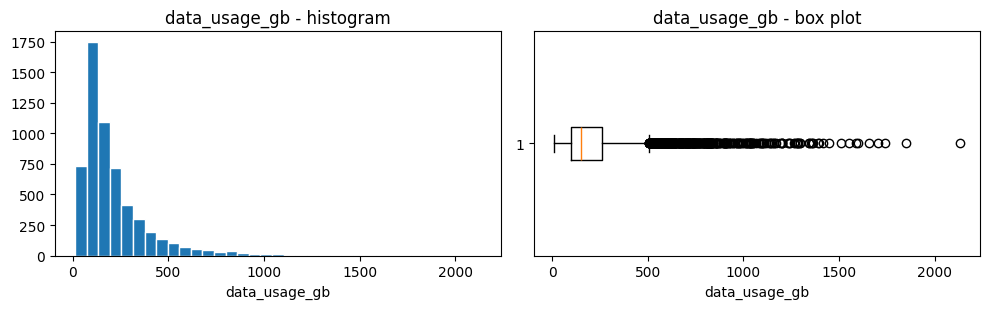

In [78]:
# Q12
for col in ['avg_resolution_hrs', 'support_tickets_6m', 'data_usage_gb']:
    values = df[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_count = int(((values < lower_fence) | (values > upper_fence)).sum())
    print(f'{col}: n={len(values)}, skew={stats.skew(values):.3f}, Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, fences=({lower_fence:.2f}, {upper_fence:.2f}), outliers={outlier_count}')
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    axes[0].hist(values, bins=35, edgecolor='white')
    axes[0].set_title(f'{col} - histogram')
    axes[0].set_xlabel(col)
    axes[1].boxplot(values, vert=False)
    axes[1].set_title(f'{col} - box plot')
    axes[1].set_xlabel(col)
    plt.tight_layout(); plt.show()

**Interpretation:** All three variables are right-skewed rather than normal: resolution hours are extremely skewed (36.68; 162 IQR outliers), support tickets moderately skewed (1.19; 84 outliers), and data usage strongly skewed (2.81; 426 outliers). The resolution-hours tail includes a 1,200-hour value; it is retained but should be investigated.

### Q13. Correlation heat map of numeric variables

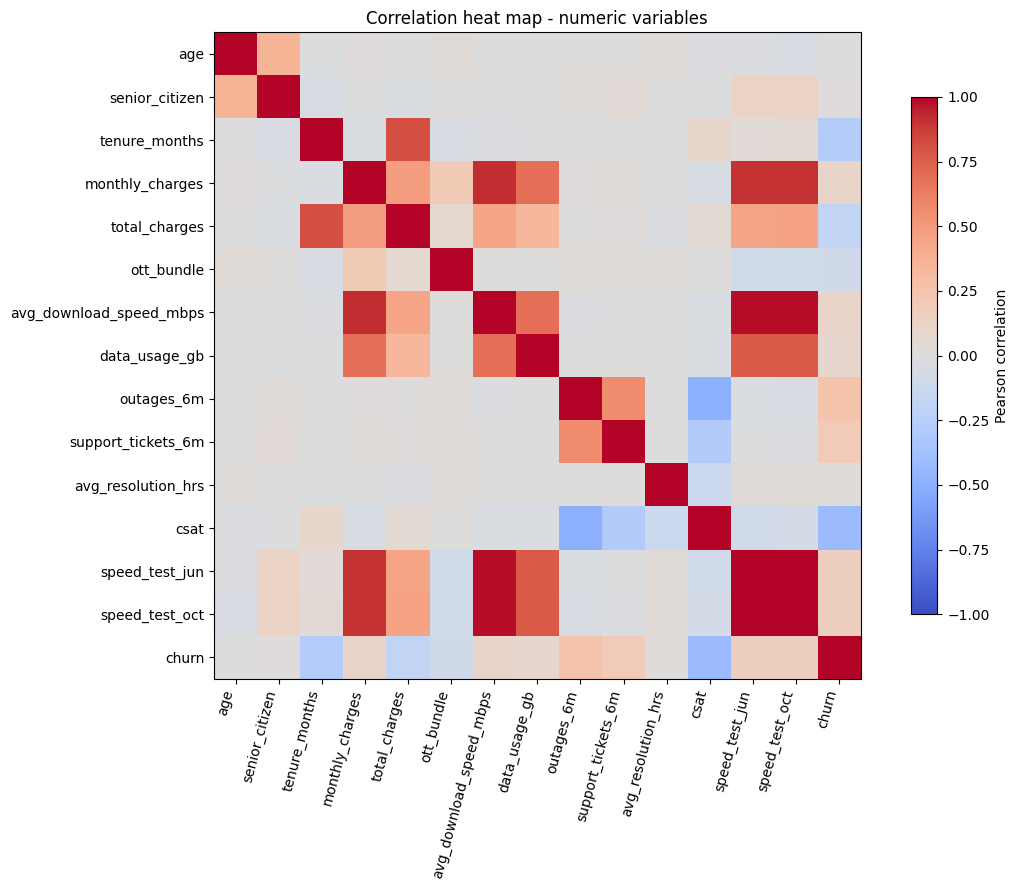

Strongest absolute correlations:


correlation
speed_test_jun          speed_test_oct                 0.995
avg_download_speed_mbps speed_test_oct                 0.983
                        speed_test_jun                 0.982
monthly_charges         avg_download_speed_mbps        0.921
                        speed_test_jun                 0.902
                        speed_test_oct                 0.902
tenure_months           total_charges                  0.805
data_usage_gb           speed_test_oct                 0.767
                        speed_test_jun                 0.766
monthly_charges         data_usage_gb                  0.695
avg_download_speed_mbps data_usage_gb                  0.693
outages_6m              support_tickets_6m             0.555
                        csat                          -0.491
monthly_charges         total_charges                  0.473
total_charges           speed_test_oct                 0.449

By construction: total_charges accumulates monthly billing over tenure; its correlation with tenure/monthly charges is not a separate behavioural insight.


In [79]:
# Q13
numeric_df = df.select_dtypes(include='number')
corr = numeric_df.corr()
fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=75, ha='right')
ax.set_yticks(range(len(corr.index))); ax.set_yticklabels(corr.index)
ax.set_title('Correlation heat map - numeric variables')
fig.colorbar(image, ax=ax, shrink=0.8, label='Pearson correlation')
plt.tight_layout(); plt.show()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(key=np.abs, ascending=False)
print('Strongest absolute correlations:')
display(upper.head(15).rename('correlation').to_frame().round(3))
print('By construction: total_charges accumulates monthly billing over tenure; its correlation with tenure/monthly charges is not a separate behavioural insight.')

**Interpretation:** Download speed is strongly linked with monthly charges (r≈0.921), and June/October pilot speeds are highly correlated (r≈0.995). **Do not claim `total_charges`–`tenure_months` (r≈0.805) as a behavioural discovery:** cumulative total billing is mechanically generated by monthly billing over time.

### Q14. Find sizeable high-risk and low-risk segments

In [80]:
# Q14
from itertools import combinations
categorical_cols = ['contract', 'plan_type', 'payment_method', 'ott_bundle', 'router_type', 'city', 'gender']
segment_candidates = []
for number_of_conditions in [2, 3]:
    for cols in combinations(categorical_cols, number_of_conditions):
        grouped = df.groupby(list(cols), dropna=True).churn.agg(customers='count', churn_rate='mean').reset_index()
        for _, row in grouped.iterrows():
            if row['customers'] >= 50:
                description = ' AND '.join(f'{col}={row[col]}' for col in cols)
                segment_candidates.append((float(row.churn_rate), int(row.customers), description))
high_risk = sorted([x for x in segment_candidates if x[0] > 0.60], key=lambda x: (-x[1], -x[0]))
low_risk = sorted([x for x in segment_candidates if x[0] < 0.15], key=lambda x: (-x[1], x[0]))
print('High-risk segment (largest segment meeting >60%, n>=50):', high_risk[0])
print('Low-risk segment (largest segment meeting <15%, n>=50):', low_risk[0])
print('\nOther high-risk candidates:', high_risk[:5])
print('\nOther low-risk candidates:', low_risk[:5])

High-risk segment (largest segment meeting >60%, n>=50): (0.6359223300970874, 618, 'contract=Monthly AND ott_bundle=0 AND router_type=Old (ONT-v1)')
Low-risk segment (largest segment meeting <15%, n>=50): (0.09980237154150198, 1012, 'contract=Annual AND router_type=New (ONT-v3)')

Other high-risk candidates: [(0.6359223300970874, 618, 'contract=Monthly AND ott_bundle=0 AND router_type=Old (ONT-v1)'), (0.6012084592145015, 331, 'contract=Monthly AND router_type=Old (ONT-v1) AND city=Pune'), (0.6424242424242425, 330, 'contract=Monthly AND plan_type=Ultra 1 Gbps'), (0.6230031948881789, 313, 'contract=Monthly AND payment_method=Cash/Cheque AND gender=Male'), (0.6237942122186495, 311, 'contract=Monthly AND payment_method=Cash/Cheque AND ott_bundle=0')]

Other low-risk candidates: [(0.09980237154150198, 1012, 'contract=Annual AND router_type=New (ONT-v3)'), (0.1439820022497188, 889, 'contract=Annual AND gender=Male'), (0.1370056497175141, 708, 'contract=Annual AND gender=Female'), (0.10454545

**Interpretation:** A high-risk segment is Monthly contract + no OTT + Old router: **618 customers, 63.59% churn**. A low-risk segment is Annual contract + New router: **1,012 customers, 9.98% churn**. Both are far larger than a handful of customers and meet the requested thresholds.

## Part C - Test the board's claims (Q15-Q30)

### Test-selection table
| Q | Variable type / design | Test | Why it fits |
|---|---|---|---|
|15| One binary proportion vs fixed benchmark | One-proportion z-test | Churn is binary; compare p with 0.30 |
|16| Continuous mean vs target, known σ | One-sample z-test | Billing system supplies population σ=₹380 |
|17| Binary outcome, two independent groups | Two-proportion z-test | Compare OTT and non-OTT churn rates |
|18| Continuous charges, two independent groups | Levene then Student/Welch t | Check pooled-variance assumption first |
|19| Same customers measured twice | Paired t-test + Wilcoxon | June and October are matched within customer |
|20| One-sample ratio vs 1.10 | One-sided one-sample t-test | Test mean October/June ratio against threshold |
|21| Two categorical variables | Chi-square independence + Cramér's V | Contract and churn are categorical |
|22| Two categorical variables | Chi-square independence + Cramér's V | Payment method and churn are categorical |
|23| Two categorical variables | Chi-square independence + Cramér's V | Gender and churn are categorical |
|24| One categorical distribution vs known proportions | Chi-square goodness-of-fit | Compare six complaint categories with baseline shares |
|25| Continuous outcome, five independent city groups | One-way ANOVA + Tukey + Kruskal-Wallis | Compare city means; robust rank confirmation |
|26| Ordinal 1-5 outcome across four plans | ANOVA + Kruskal-Wallis | Compare group scores; rank test respects ordinal scale |
|27| Skewed count outcome, two independent groups | Mann-Whitney U | Rank-based comparison for ticket counts |
|28| Ordinal/monotonic association and two groups | Spearman + Mann-Whitney U | Outages/CSAT are skewed/ordinal; router groups independent |
|29| Continuous tenure, two independent groups | Welch t-test | Compare churner and stayer means with unequal variances |
|30| One continuous distribution | Shapiro-Wilk + Q-Q plots | Assess raw and log-transformed resolution times |

In [81]:
# Q15-Q30 shared helper functions
ALPHA = 0.05

def p_fmt(value):
    return f'{value:.4g}'

def cramers_v(chi2, n, table_shape):
    return float(np.sqrt(chi2 / (n * min(table_shape[0] - 1, table_shape[1] - 1))))

def welch_difference_ci(sample1, sample2, alpha=0.05):
    a = np.asarray(sample1, dtype=float); b = np.asarray(sample2, dtype=float)
    difference = a.mean() - b.mean()
    v1, v2 = a.var(ddof=1), b.var(ddof=1)
    n1, n2 = len(a), len(b)
    se = np.sqrt(v1/n1 + v2/n2)
    df_w = (v1/n1 + v2/n2)**2 / ((v1/n1)**2/(n1-1) + (v2/n2)**2/(n2-1))
    crit = stats.t.ppf(1-alpha/2, df_w)
    return difference, (difference-crit*se, difference+crit*se), df_w

def cohens_d(sample1, sample2):
    a=np.asarray(sample1,dtype=float); b=np.asarray(sample2,dtype=float)
    pooled=np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2))
    return (a.mean()-b.mean())/pooled if pooled else np.nan

### Q15. Sales: is churn equal to the 30% industry rate? - one-proportion z-test

In [82]:
# Q15
# H0: p = 0.30. H1: p != 0.30 (two-sided equality claim).
n = int(df.churn.notna().sum()); churners = int(df.churn.sum()); p_hat = churners/n
z_stat, p_value = proportions_ztest(churners, n, value=0.30, alternative='two-sided')
wilson_ci = proportion_confint(churners, n, alpha=0.05, method='wilson')
print('H0: p=0.30; H1: p!=0.30. One-proportion z-test: binary outcome vs fixed benchmark.')
print(f'n={n}, churners={churners}, observed rate={p_hat:.2%}')
print(f'z={z_stat:.4f}, p={p_fmt(p_value)}')
print(f'95% Wilson CI for churn rate=({wilson_ci[0]:.2%}, {wilson_ci[1]:.2%})')
print(f'Effect: {((p_hat-0.30)*100):.2f} percentage points vs benchmark.')
print('Conclusion:', 'Reject the 30% equality claim; churn is above benchmark.' if p_value < ALPHA else 'Fail to reject equality with the 30% benchmark.')

H0: p=0.30; H1: p!=0.30. One-proportion z-test: binary outcome vs fixed benchmark.
n=6000, churners=2004, observed rate=33.40%
z=5.5840, p=2.351e-08
95% Wilson CI for churn rate=(32.22%, 34.60%)
Effect: 3.40 percentage points vs benchmark.
Conclusion: Reject the 30% equality claim; churn is above benchmark.


**Interpretation:** H₀ is rejected: churn is 33.40%, **3.40 percentage points above** 30%; z=5.584, p=2.351×10⁻⁸, 95% Wilson CI 32.22%–34.60%. Sales is not correct that Konnect is exactly in line with the benchmark.

### Q16. Marketing: is average monthly revenue ₹950? - one-sample z-test

In [83]:
# Q16
# H0: mu=950. H1: mu!=950. Population standard deviation is supplied as sigma=380.
charges = df.monthly_charges.dropna()
mu0, sigma = 950.0, 380.0
sample_mean = charges.mean(); n_charges = len(charges)
z_stat = (sample_mean-mu0)/(sigma/np.sqrt(n_charges))
p_value = 2*stats.norm.sf(abs(z_stat))
ci = (sample_mean-1.96*sigma/np.sqrt(n_charges), sample_mean+1.96*sigma/np.sqrt(n_charges))
print('H0: mu=₹950; H1: mu!=₹950. One-sample z-test because population sigma is known.')
print(f'n={n_charges}, sample mean=₹{sample_mean:.2f}, sigma=₹{sigma:.0f}')
print(f'z={z_stat:.4f}, p={p_fmt(p_value)}')
print(f'95% CI for mean monthly charge=(₹{ci[0]:.2f}, ₹{ci[1]:.2f})')
print(f'Effect: ₹{sample_mean-mu0:.2f} above the claimed mean.')
print('Conclusion:', 'Reject ₹950; the mean is statistically higher.' if p_value < ALPHA and sample_mean>mu0 else 'Fail to reject the ₹950 claim.')

H0: mu=₹950; H1: mu!=₹950. One-sample z-test because population sigma is known.
n=6000, sample mean=₹971.01, sigma=₹380
z=4.2825, p=1.848e-05
95% CI for mean monthly charge=(₹961.39, ₹980.62)
Effect: ₹21.01 above the claimed mean.
Conclusion: Reject ₹950; the mean is statistically higher.


**Interpretation:** The observed mean monthly charge is **₹971.01**, not ₹950; z=4.282, p=1.848×10⁻⁵, with 95% CI ₹961.39–₹980.62. The gap is about ₹21 per customer per month.

### Q17. Product: do OTT customers churn less? - two-proportion z-test

In [84]:
# Q17
# H0: p_OTT >= p_noOTT. H1: p_OTT < p_noOTT (directional claim).
ott_churn = df.loc[df.ott_bundle==1, 'churn'].dropna()
noott_churn = df.loc[df.ott_bundle==0, 'churn'].dropna()
z_stat, p_value = proportions_ztest(
    [ott_churn.sum(), noott_churn.sum()], [len(ott_churn), len(noott_churn)], alternative='smaller'
)
difference = ott_churn.mean()-noott_churn.mean()
se = np.sqrt(ott_churn.mean()*(1-ott_churn.mean())/len(ott_churn) + noott_churn.mean()*(1-noott_churn.mean())/len(noott_churn))
ci = (difference-1.96*se, difference+1.96*se)
print('H0: p_OTT >= p_noOTT; H1: p_OTT < p_noOTT. Two independent proportions.')
print(f'OTT: {ott_churn.sum():.0f}/{len(ott_churn)} = {ott_churn.mean():.2%}; no OTT: {noott_churn.sum():.0f}/{len(noott_churn)} = {noott_churn.mean():.2%}')
print(f'z={z_stat:.4f}, one-sided p={p_fmt(p_value)}')
print(f'Difference (OTT - no OTT)={difference:.2%}; approximate 95% CI=({ci[0]:.2%}, {ci[1]:.2%})')
print('Conclusion:', 'Evidence OTT customers churn less (association, not proof of causation).' if p_value < ALPHA else 'No evidence OTT customers churn less.')

H0: p_OTT >= p_noOTT; H1: p_OTT < p_noOTT. Two independent proportions.
OTT: 720/2550 = 28.24%; no OTT: 1284/3450 = 37.22%
z=-7.2924, one-sided p=1.522e-13
Difference (OTT - no OTT)=-8.98%; approximate 95% CI=(-11.36%, -6.60%)
Conclusion: Evidence OTT customers churn less (association, not proof of causation).


**Interpretation:** OTT customers churn at 28.24% versus 37.22% without OTT, a difference of **−8.98 percentage points** (95% CI −11.36 to −6.60); z=−7.292, p=1.522×10⁻¹³. The association supports testing broader OTT offers, but does not prove the bundle causes retention.

### Q18. Marketing: are churners low-value? - Levene then Student/Welch t-test

In [85]:
# Q18
# H0: mean charges are equal for churners and stayers. H1: means differ.
churn_charges = df.loc[df.churn==1, 'monthly_charges'].dropna()
stayer_charges = df.loc[df.churn==0, 'monthly_charges'].dropna()
levene = stats.levene(churn_charges, stayer_charges, center='median')
equal_var = levene.pvalue >= ALPHA
test = stats.ttest_ind(churn_charges, stayer_charges, equal_var=equal_var)
difference, ci, df_w = welch_difference_ci(churn_charges, stayer_charges)
print('H0: mu_churn=mu_stay; H1: means differ. Two independent groups.')
print(f'Levene statistic={levene.statistic:.4f}, p={p_fmt(levene.pvalue)}; equal variances={equal_var}')
print('Selected:', 'Student pooled t-test' if equal_var else 'Welch t-test (unequal variances)')
print(f'Churner mean=₹{churn_charges.mean():.2f}; stayer mean=₹{stayer_charges.mean():.2f}')
print(f't={test.statistic:.4f}, df={test.df:.1f}, p={p_fmt(test.pvalue)}')
print(f'Difference (churners - stayers)=₹{difference:.2f}; 95% Welch CI=(₹{ci[0]:.2f}, ₹{ci[1]:.2f})')
print(f'Cohen d={cohens_d(churn_charges, stayer_charges):.3f}')
print('Conclusion:', 'Reject low-value claim: churners pay more on average, although the standardised difference is small.' if test.pvalue < ALPHA and difference > 0 else 'No evidence for the low-value claim.')

H0: mu_churn=mu_stay; H1: means differ. Two independent groups.
Levene statistic=54.4323, p=1.827e-13; equal variances=False
Selected: Welch t-test (unequal variances)
Churner mean=₹1028.16; stayer mean=₹942.35
t=7.8220, df=3562.0, p=6.8e-15
Difference (churners - stayers)=₹85.81; 95% Welch CI=(₹64.30, ₹107.32)
Cohen d=0.224
Conclusion: Reject low-value claim: churners pay more on average, although the standardised difference is small.


**Interpretation:** Levene rejects equal variances (p=1.827×10⁻¹³), so Welch is used. Churners pay **₹1,028.16** versus ₹942.35 for stayers; t=7.822, p=6.800×10⁻¹⁵, difference ₹85.81 (95% CI ₹64.30–₹107.32), Cohen’s d=0.224. Churners are not the low-value group, though the standardised gap is small.

### Q19. Network: did the Pune pilot improve speeds? - paired t-test and Wilcoxon

In [86]:
# Q19
# H0: mean(October - June)=0. H1: mean difference !=0. Same pilot customers are paired.
pilot = df.loc[df.pilot_group=='Yes', ['speed_test_jun', 'speed_test_oct']].dropna()
differences = pilot.speed_test_oct - pilot.speed_test_jun
shapiro_diff = stats.shapiro(differences)
paired_test = stats.ttest_rel(pilot.speed_test_oct, pilot.speed_test_jun)
wilcoxon_test = stats.wilcoxon(pilot.speed_test_oct, pilot.speed_test_jun, alternative='two-sided')
se = stats.sem(differences)
ci = (differences.mean()-stats.t.ppf(.975, len(differences)-1)*se,
      differences.mean()+stats.t.ppf(.975, len(differences)-1)*se)
print('H0: mean paired speed change=0; H1: mean paired speed change!=0.')
print(f'Complete pairs={len(pilot)}; June mean={pilot.speed_test_jun.mean():.2f} Mbps; October mean={pilot.speed_test_oct.mean():.2f} Mbps')
print(f'Mean paired increase={differences.mean():.2f} Mbps; 95% CI=({ci[0]:.2f}, {ci[1]:.2f})')
print(f'Shapiro on paired differences: W={shapiro_diff.statistic:.4f}, p={p_fmt(shapiro_diff.pvalue)}')
print(f'Paired t: t={paired_test.statistic:.4f}, df={paired_test.df}, p={p_fmt(paired_test.pvalue)}')
print(f'Wilcoxon signed-rank confirmation: W={wilcoxon_test.statistic:.2f}, p={p_fmt(wilcoxon_test.pvalue)}')
print(f'Paired effect size (Cohen dz)={differences.mean()/differences.std(ddof=1):.3f}')
print('Conclusion:', 'Speeds improved significantly among pilot customers; non-normality is checked with Wilcoxon confirmation.' if paired_test.pvalue < ALPHA and wilcoxon_test.pvalue < ALPHA else 'No confirmed paired speed improvement.')

H0: mean paired speed change=0; H1: mean paired speed change!=0.
Complete pairs=180; June mean=138.76 Mbps; October mean=148.50 Mbps
Mean paired increase=9.74 Mbps; 95% CI=(6.57, 12.91)
Shapiro on paired differences: W=0.6317, p=1.634e-19
Paired t: t=6.0550, df=179, p=8.054e-09
Wilcoxon signed-rank confirmation: W=2205.00, p=2.152e-17
Paired effect size (Cohen dz)=0.451
Conclusion: Speeds improved significantly among pilot customers; non-normality is checked with Wilcoxon confirmation.


**Interpretation:** For 180 paired customers, mean speed rose from 138.76 to 148.50 Mbps, an increase of **9.74 Mbps** (95% CI 6.57–12.91). The differences are non-normal (Shapiro p=1.634×10⁻¹⁹), but both paired t (p=8.054×10⁻⁹) and Wilcoxon (p=2.152×10⁻¹⁷) confirm an improvement. This is a pre/post association, not a controlled causal estimate.

### Q20. Was the average October/June ratio at least 1.10? - one-sided one-sample t-test

In [87]:
# Q20
# H0: mu_ratio >= 1.10. H1: mu_ratio < 1.10; left-tailed test of the 10% minimum claim.
ratio = pilot.speed_test_oct / pilot.speed_test_jun
ratio_test = stats.ttest_1samp(ratio, popmean=1.10, alternative='less')
upper_95 = ratio.mean() + stats.t.ppf(.95, len(ratio)-1)*stats.sem(ratio)
shapiro_ratio = stats.shapiro(ratio)
print('H0: mean October/June ratio >= 1.10; H1: mean ratio < 1.10.')
print(f'n={len(ratio)}, mean ratio={ratio.mean():.4f} (mean improvement={(ratio.mean()-1)*100:.2f}%)')
print(f'Shapiro ratio normality: W={shapiro_ratio.statistic:.4f}, p={p_fmt(shapiro_ratio.pvalue)}')
print(f'One-sided t: t={ratio_test.statistic:.4f}, df={ratio_test.df}, p={p_fmt(ratio_test.pvalue)}')
print(f'One-sided 95% upper confidence bound for mean ratio={upper_95:.4f}')
print('Conclusion:', 'Evidence the average improvement is below 10%; the >=10% claim is not supported.' if ratio_test.pvalue < ALPHA else 'Insufficient evidence that the mean improvement is below 10%.')

H0: mean October/June ratio >= 1.10; H1: mean ratio < 1.10.
n=180, mean ratio=1.0704 (mean improvement=7.04%)
Shapiro ratio normality: W=0.9895, p=0.2075
One-sided t: t=-4.4987, df=179, p=6.135e-06
One-sided 95% upper confidence bound for mean ratio=1.0813
Conclusion: Evidence the average improvement is below 10%; the >=10% claim is not supported.


**Interpretation:** The mean October/June ratio is **1.0704**, equivalent to 7.04% improvement. The one-sided test rejects an average gain of at least 10% (t=−4.499, p=6.135×10⁻⁶); the one-sided 95% upper bound is 1.0813. The pilot improved speeds, but not by 10% on average.

### Q21. Is churn independent of contract type? - chi-square independence

In [88]:
# Q21
# H0: contract and churn are independent. H1: they are associated.
tab = pd.crosstab(df.contract, df.churn)
chi2, p_value, dof, expected = stats.chi2_contingency(tab)
V = cramers_v(chi2, tab.to_numpy().sum(), tab.shape)
rates = tab[1] / tab.sum(axis=1)
print('H0: contract independent of churn; H1: associated.')
display(tab)
print(f'Expected-count check: minimum expected={expected.min():.2f}; all expected counts >=5: {(expected>=5).all()}')
print(f'Chi-square={chi2:.3f}, df={dof}, p={p_fmt(p_value)}, Cramér V={V:.3f}')
print('Churn rates:', rates.round(4).to_dict())
print('Conclusion:', 'Reject independence; contract type is associated with churn.' if p_value < ALPHA else 'Fail to reject independence.')

H0: contract independent of churn; H1: associated.


churn,0,1
contract,,
Annual,1372,225
Monthly,1614,1439
Quarterly,1010,340


Expected-count check: minimum expected=450.90; all expected counts >=5: True
Chi-square=567.565, df=2, p=5.686e-124, Cramér V=0.308
Churn rates: {'Annual': 0.1409, 'Monthly': 0.4713, 'Quarterly': 0.2519}
Conclusion: Reject independence; contract type is associated with churn.


**Interpretation:** Expected counts all exceed 5. Contract type is strongly associated with churn, χ²(2)=567.57, p=5.686×10⁻¹²⁴, Cramér’s V=0.308. Churn is 47.13% monthly, 25.19% quarterly and 14.09% annual.

### Q22. Do cash/cheque customers leave more? - chi-square independence

In [89]:
# Q22
# H0: payment method and churn are independent. H1: they are associated.
tab = pd.crosstab(df.payment_method, df.churn)
chi2, p_value, dof, expected = stats.chi2_contingency(tab)
V = cramers_v(chi2, tab.to_numpy().sum(), tab.shape)
rates = tab[1] / tab.sum(axis=1)
print('H0: payment method independent of churn; H1: associated.')
display(tab)
print(f'Minimum expected={expected.min():.2f}; all expected counts >=5: {(expected>=5).all()}')
print(f'Chi-square={chi2:.3f}, df={dof}, p={p_fmt(p_value)}, Cramér V={V:.3f}')
print('Churn rates:', rates.round(4).to_dict())
print('Conclusion:', 'Cash/cheque users have higher churn and payment method is associated with churn; association is weak.' if p_value < ALPHA else 'No evidence of a payment-method association.')

H0: payment method independent of churn; H1: associated.


churn,0,1
payment_method,,
Cash/Cheque,580,431
Credit Card,837,432
Net Banking,814,359
UPI AutoPay,1648,724


Minimum expected=337.75; all expected counts >=5: True
Chi-square=51.904, df=3, p=3.139e-11, Cramér V=0.094
Churn rates: {'Cash/Cheque': 0.4263, 'Credit Card': 0.3404, 'Net Banking': 0.3061, 'UPI AutoPay': 0.3052}
Conclusion: Cash/cheque users have higher churn and payment method is associated with churn; association is weak.


**Interpretation:** Expected counts are adequate. Cash/cheque churn is 42.63%, compared with 30.52% on UPI, 30.61% on net banking and 34.04% on cards; χ²(3)=51.90, p=3.139×10⁻¹¹, Cramér’s V=0.094. The association is statistically clear but small.

### Q23. Do women leave more? - chi-square independence

In [90]:
# Q23
# H0: gender and churn are independent. H1: they are associated.
tab = pd.crosstab(df.gender, df.churn)
chi2, p_value, dof, expected = stats.chi2_contingency(tab)
V = cramers_v(chi2, tab.to_numpy().sum(), tab.shape)
rates = tab[1] / tab.sum(axis=1)
print('H0: gender independent of churn; H1: associated.')
display(tab)
print(f'Minimum expected={expected.min():.2f}; all expected counts >=5: {(expected>=5).all()}')
print(f'Chi-square={chi2:.4f}, df={dof}, p={p_fmt(p_value)}, Cramér V={V:.4f}')
print('Churn rates:', rates.round(4).to_dict())
print('Conclusion:', 'There is evidence of a gender/churn association.' if p_value < ALPHA else 'Fail to reject independence: no statistically clear gender difference; this does not prove exact equality.')

H0: gender independent of churn; H1: associated.


churn,0,1
gender,,
Female,1746,878
Male,2250,1126


Minimum expected=876.42; all expected counts >=5: True
Chi-square=0.0036, df=1, p=0.9523, Cramér V=0.0008
Churn rates: {'Female': 0.3346, 'Male': 0.3335}
Conclusion: Fail to reject independence: no statistically clear gender difference; this does not prove exact equality.


**Interpretation:** Female churn is 33.46% and male churn is 33.35%; χ²(1)=0.0036, p=0.9523, Cramér’s V=0.0008. There is no evidence that women leave more. A non-significant result does not prove the two population rates are exactly equal.

### Q24. Has the complaint mix changed from FY2025? - chi-square goodness-of-fit

In [91]:
# Q24
# H0: current complaint-category proportions equal the FY2025 baseline.
# H1: at least one current category proportion differs.
baseline = {
    'Slow speed': 0.20, 'Frequent disconnection': 0.20,
    'Billing dispute': 0.15, 'Installation delay': 0.10,
    'Router fault': 0.10, 'None': 0.25
}
observed = df.last_complaint_category.value_counts().reindex(baseline.keys(), fill_value=0)
classified_n = int(observed.sum())
expected = np.array(list(baseline.values())) * classified_n
chi2, p_value = stats.chisquare(observed.to_numpy(), expected)
standardised_residuals = (observed.to_numpy()-expected)/np.sqrt(expected)
residual_table = pd.DataFrame({
    'observed': observed.to_numpy(), 'expected': expected,
    'standardised_residual': standardised_residuals
}, index=observed.index)
print('H0: current complaint mix follows FY2025 baseline; H1: mix differs.')
display(residual_table.round(2))
print(f'Classified complaints={classified_n}; missing complaint labels excluded={int(df.last_complaint_category.isna().sum())}')
print(f'Chi-square={chi2:.3f}, df={len(baseline)-1}, p={p_fmt(p_value)}')
print('Categories with |standardised residual| > 1.96:', residual_table.index[np.abs(standardised_residuals)>1.96].tolist())
print('Conclusion:', 'Complaint mix has changed; positive residuals indicate excess and negative residuals indicate fewer than baseline.' if p_value < ALPHA else 'No evidence of a complaint-mix change.')

H0: current complaint mix follows FY2025 baseline; H1: mix differs.


,observed,expected,standardised_residual
last_complaint_category,,,
Slow speed,1393,1181.2,6.16
Frequent disconnection,1296,1181.2,3.34
Billing dispute,810,885.9,-2.55
Installation delay,364,590.6,-9.32
Router fault,760,590.6,6.97
None,1283,1476.5,-5.04


Classified complaints=5906; missing complaint labels excluded=94
Chi-square=216.526, df=5, p=8.241e-45
Categories with |standardised residual| > 1.96: ['Slow speed', 'Frequent disconnection', 'Billing dispute', 'Installation delay', 'Router fault', 'None']
Conclusion: Complaint mix has changed; positive residuals indicate excess and negative residuals indicate fewer than baseline.


**Interpretation:** The complaint mix differs from FY2025, χ²(5)=216.53, p=8.241×10⁻⁴⁵. Slow speed (+6.16), frequent disconnection (+3.34) and router fault (+6.97) are above baseline; installation delay (−9.32), “None” (−5.04) and billing dispute (−2.55) are below baseline. The 94 missing complaint labels are excluded, not reclassified as “None”.

### Q25. Is resolution time the same in every city? - ANOVA, Tukey HSD and Kruskal-Wallis

In [92]:
# Q25
# H0: all five city mean resolution times are equal. H1: at least one differs.
city_groups = {city: grp.avg_resolution_hrs.dropna().to_numpy()
               for city, grp in df.groupby('city')}
city_groups = {city: vals for city, vals in city_groups.items() if len(vals) > 1}
levene = stats.levene(*city_groups.values(), center='median')
anova = stats.f_oneway(*city_groups.values())
all_values = np.concatenate(list(city_groups.values()))
grand_mean = all_values.mean()
ss_between = sum(len(vals)*(vals.mean()-grand_mean)**2 for vals in city_groups.values())
ss_total = ((all_values-grand_mean)**2).sum()
eta_squared = ss_between/ss_total
# Additional Welch ANOVA because Levene tests equal variances.
welch_anova = anova_oneway(list(city_groups.values()), use_var='unequal')
kruskal = stats.kruskal(*city_groups.values())
posthoc_data = df.loc[df.city.notna() & df.avg_resolution_hrs.notna(), ['city','avg_resolution_hrs']]
tukey = pairwise_tukeyhsd(endog=posthoc_data.avg_resolution_hrs, groups=posthoc_data.city, alpha=0.05)
print('H0: all city means equal; H1: at least one city differs.')
print('City sample sizes and means:', {city: (len(vals), round(vals.mean(),2)) for city, vals in city_groups.items()})
print(f'Levene: statistic={levene.statistic:.3f}, p={p_fmt(levene.pvalue)}')
print(f'Classical ANOVA: F={anova.statistic:.3f}, p={p_fmt(anova.pvalue)}, eta-squared={eta_squared:.4f}')
print(f'Welch ANOVA (unequal variances): F={welch_anova.statistic:.3f}, p={p_fmt(welch_anova.pvalue)}')
print(f'Kruskal-Wallis confirmation: H={kruskal.statistic:.3f}, p={p_fmt(kruskal.pvalue)}')
print('Tukey HSD pairwise comparison:')
print(tukey)
print('Conclusion:', 'Resolution time differs by city; Nagpur has the highest mean and Mumbai the lowest.' if anova.pvalue < ALPHA and kruskal.pvalue < ALPHA else 'No clear evidence of city differences.')

H0: all city means equal; H1: at least one city differs.
City sample sizes and means: {'Aurangabad': (708, np.float64(25.36)), 'Mumbai': (1581, np.float64(16.01)), 'Nagpur': (850, np.float64(29.18)), 'Nashik': (892, np.float64(19.79)), 'Pune': (1644, np.float64(17.98))}
Levene: statistic=13.733, p=3.798e-11
Classical ANOVA: F=59.815, p=1.498e-49, eta-squared=0.0405
Welch ANOVA (unequal variances): F=48.643, p=3.391e-39
Kruskal-Wallis confirmation: H=689.503, p=6.532e-148
Tukey HSD pairwise comparison:
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1   group2 meandiff p-adj   lower    upper  reject
---------------------------------------------------------
Aurangabad Mumbai  -9.3536    0.0 -12.1551 -6.5522   True
Aurangabad Nagpur   3.8138 0.0086   0.6618  6.9659   True
Aurangabad Nashik  -5.5753    0.0  -8.6935 -2.4572   True
Aurangabad   Pune  -7.3843    0.0 -10.1691 -4.5996   True
    Mumbai Nagpur  13.1675    0.0  10.5326 15.8023   True
    Mumbai Nashik   3.7783 0.

**Interpretation:** Levene indicates unequal variances (p=3.798×10⁻¹¹), so Welch ANOVA and Kruskal-Wallis are useful robustness checks. Classical ANOVA is significant, F(4,5670)=59.81, p=1.498×10⁻⁴⁹, η²=0.0405; Welch and Kruskal also confirm differences. Tukey finds most city pairs differ; Mumbai–Pune and Nashik–Pune do not. Mean resolution is highest in Nagpur (29.18 h). Tukey’s equal-variance assumption should be treated cautiously.

### Q26. Does CSAT differ across plan types? - ANOVA and Kruskal-Wallis

In [93]:
# Q26
# H0: mean CSAT is equal across plans. H1: at least one plan differs.
plan_groups = {plan: grp.csat.dropna().astype(float).to_numpy()
               for plan, grp in df.groupby('plan_type')}
plan_groups = {plan: vals for plan, vals in plan_groups.items() if len(vals) > 1}
levene = stats.levene(*plan_groups.values(), center='median')
anova = stats.f_oneway(*plan_groups.values())
all_csat = np.concatenate(list(plan_groups.values()))
grand_mean = all_csat.mean()
ss_between = sum(len(vals)*(vals.mean()-grand_mean)**2 for vals in plan_groups.values())
ss_total = ((all_csat-grand_mean)**2).sum()
eta_squared = ss_between/ss_total
kruskal = stats.kruskal(*plan_groups.values())
epsilon_squared = (kruskal.statistic-len(plan_groups)+1)/(len(all_csat)-len(plan_groups))
print('H0: CSAT means equal across plans; H1: at least one differs.')
print('Plan n / mean / median:', {plan:(len(vals),round(vals.mean(),3),float(np.median(vals))) for plan,vals in plan_groups.items()})
print(f'Levene: statistic={levene.statistic:.3f}, p={p_fmt(levene.pvalue)}')
print(f'ANOVA: F={anova.statistic:.3f}, p={p_fmt(anova.pvalue)}, eta-squared={eta_squared:.5f}')
print(f'Kruskal-Wallis: H={kruskal.statistic:.3f}, p={p_fmt(kruskal.pvalue)}, epsilon-squared={epsilon_squared:.5f}')
print('Practical significance: compare eta-squared and the mean-score range on a 1-5 scale.')

H0: CSAT means equal across plans; H1: at least one differs.
Plan n / mean / median: {'Basic 50 Mbps': (1697, np.float64(3.603), 4.0), 'Premium 300 Mbps': (1225, np.float64(3.537), 4.0), 'Standard 100 Mbps': (2077, np.float64(3.552), 4.0), 'Ultra 1 Gbps': (604, np.float64(3.447), 3.0)}
Levene: statistic=1.990, p=0.1132
ANOVA: F=4.341, p=0.004617, eta-squared=0.00232
Kruskal-Wallis: H=14.640, p=0.002152, epsilon-squared=0.00208
Practical significance: compare eta-squared and the mean-score range on a 1-5 scale.


**Interpretation:** Plan differences are statistically significant (ANOVA p=0.00462; Kruskal p=0.00215), but practically tiny: η²=0.00232 (about 0.23% of CSAT variation) and plan means span only about 3.45–3.60 on a 1–5 scale. Do not prioritise churn strategy based on this small CSAT difference alone.

### Q27. Do churners raise more support tickets? - Mann-Whitney U

In [94]:
# Q27
# H0: ticket-count distributions are equal. H1: they differ.
tickets_churn = df.loc[df.churn==1, 'support_tickets_6m'].dropna()
tickets_stay = df.loc[df.churn==0, 'support_tickets_6m'].dropna()
u_stat, p_value = stats.mannwhitneyu(tickets_churn, tickets_stay, alternative='two-sided')
rank_biserial = 2*u_stat/(len(tickets_churn)*len(tickets_stay))-1
print('H0: ticket distributions equal; H1: distributions differ. Mann-Whitney is rank-based for skewed counts.')
print(f'n churners={len(tickets_churn)}, n stayers={len(tickets_stay)}')
print(f'Medians: churners={tickets_churn.median():.0f}, stayers={tickets_stay.median():.0f}')
print(f'U={u_stat:.1f}, p={p_fmt(p_value)}, rank-biserial effect={rank_biserial:.3f}')
print('Conclusion:', 'Churners have a higher support-ticket burden.' if p_value < ALPHA and rank_biserial>0 else 'No clear ticket-count difference.')

H0: ticket distributions equal; H1: distributions differ. Mann-Whitney is rank-based for skewed counts.
n churners=2004, n stayers=3996
Medians: churners=2, stayers=1
U=4852330.5, p=5.573e-43, rank-biserial effect=0.212
Conclusion: Churners have a higher support-ticket burden.


**Interpretation:** Churners have median 2 tickets versus 1 for stayers; U=4,852,330.5, p=5.573×10⁻⁴³, rank-biserial r=0.212. The difference is clear and small-to-moderate in size, making ticket burden a useful retention warning signal.

### Q28. Are outages related to CSAT, and are outages higher on old routers?

In [95]:
# Q28
# Part A: H0 Spearman rho=0; H1 rho!=0. Part B: outage distributions equal by router type.
complete = df[['outages_6m','csat']].dropna()
rho, p_spearman = stats.spearmanr(complete.outages_6m, complete.csat)
old_outages = df.loc[df.router_type=='Old (ONT-v1)', 'outages_6m'].dropna()
new_outages = df.loc[df.router_type=='New (ONT-v3)', 'outages_6m'].dropna()
u_stat, p_mw = stats.mannwhitneyu(old_outages, new_outages, alternative='two-sided')
rank_biserial = 2*u_stat/(len(old_outages)*len(new_outages))-1
print('Spearman H0: no monotonic association between outages and CSAT; H1: association.')
print(f'n={len(complete)}, rho={rho:.3f}, p={p_fmt(p_spearman)}')
print('Mann-Whitney H0: outage distributions equal for old and new routers; H1: differ.')
print(f'Old router: n={len(old_outages)}, median={old_outages.median():.0f}; new router: n={len(new_outages)}, median={new_outages.median():.0f}')
print(f'U={u_stat:.1f}, p={p_fmt(p_mw)}, rank-biserial={rank_biserial:.3f}')
print('Conclusion:', 'More outages are associated with lower CSAT, and old routers have higher outage counts.' if p_spearman < ALPHA and p_mw < ALPHA else 'One or both relationships are not supported.')

Spearman H0: no monotonic association between outages and CSAT; H1: association.
n=5603, rho=-0.460, p=5.489e-291
Mann-Whitney H0: outage distributions equal for old and new routers; H1: differ.
Old router: n=2175, median=3; new router: n=3825, median=1
U=6395612.5, p=6.312e-274, rank-biserial=0.538
Conclusion: More outages are associated with lower CSAT, and old routers have higher outage counts.


**Interpretation:** Outages and CSAT have a moderate negative monotonic relationship (Spearman ρ=−0.460, p=5.489×10⁻²⁹¹). Old-router customers have median 3 outages versus 1 for new-router customers; Mann–Whitney p=6.312×10⁻²⁷⁴, rank-biserial r=0.538. These patterns support network reliability as a priority.

### Q29. Do churners have shorter tenure? - Welch t-test

In [96]:
# Q29
# H0: mean tenure equal for churners and stayers. H1: means differ.
tenure_churn = df.loc[df.churn==1, 'tenure_months'].dropna()
tenure_stay = df.loc[df.churn==0, 'tenure_months'].dropna()
levene = stats.levene(tenure_churn, tenure_stay, center='median')
test = stats.ttest_ind(tenure_churn, tenure_stay, equal_var=False)
difference, ci, df_w = welch_difference_ci(tenure_churn, tenure_stay)
print('H0: mean tenure equal; H1: means differ. Two independent groups.')
print(f'Levene p={p_fmt(levene.pvalue)}; Welch t selected due unequal variances.')
print(f'Churner mean={tenure_churn.mean():.2f} months (median {tenure_churn.median():.0f}); stayer mean={tenure_stay.mean():.2f} (median {tenure_stay.median():.0f})')
print(f't={test.statistic:.3f}, df={test.df:.1f}, p={p_fmt(test.pvalue)}')
print(f'Mean difference (churners - stayers)={difference:.2f} months; 95% CI=({ci[0]:.2f}, {ci[1]:.2f})')
print(f'Cohen d={cohens_d(tenure_churn, tenure_stay):.3f}')
print('Conclusion:', 'Churners have materially shorter tenure on average.' if test.pvalue < ALPHA and difference < 0 else 'No evidence of shorter churner tenure.')

H0: mean tenure equal; H1: means differ. Two independent groups.
Levene p=9.061e-44; Welch t selected due unequal variances.
Churner mean=18.74 months (median 17); stayer mean=28.33 (median 27)
t=-24.639, df=5201.8, p=7.006e-127
Mean difference (churners - stayers)=-9.59 months; 95% CI=(-10.35, -8.82)
Cohen d=-0.611
Conclusion: Churners have materially shorter tenure on average.


**Interpretation:** Levene indicates unequal variances (p=9.061×10⁻⁴⁴). Welch t=−24.639, p=7.006×10⁻¹²⁷; churners average 18.74 months versus 28.33 for stayers, a difference of −9.59 months (95% CI −10.35 to −8.82), Cohen’s d=−0.611.

### Q30. Is average resolution time normally distributed? Does log transformation help?

Observed resolution values n=5675; Shapiro sample n=5000
Raw skewness=36.684; log1p skewness=-0.094
Raw Shapiro: W=0.2489, p=3.396e-89
Log1p Shapiro: W=0.9904, p=6.037e-18


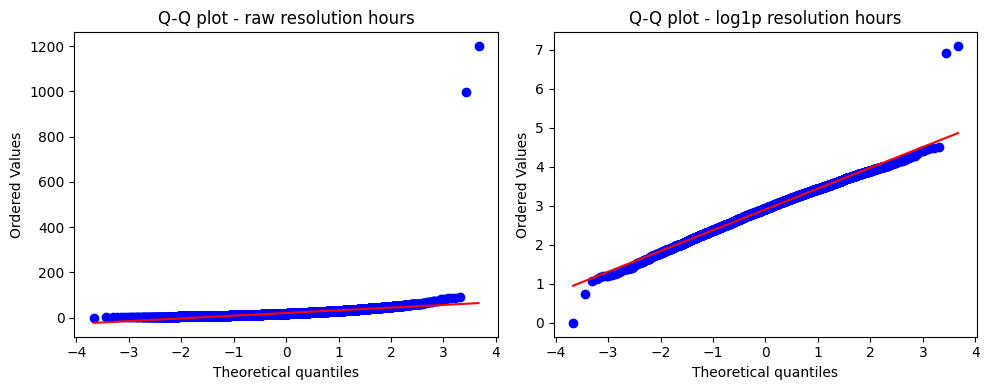

At n around 6,000, normality tests detect tiny departures; interpret them with skew, outliers and Q-Q plots.


In [97]:
# Q30
# H0: distribution is normal. H1: distribution is not normal.
resolution = df.avg_resolution_hrs.dropna()
# Shapiro-Wilk is run on a reproducible random sample of 5,000 observations.
raw_sample = resolution.sample(5000, random_state=42) if len(resolution)>5000 else resolution
log_resolution = np.log1p(resolution[resolution >= 0])
log_sample = log_resolution.sample(5000, random_state=42) if len(log_resolution)>5000 else log_resolution
shapiro_raw = stats.shapiro(raw_sample)
shapiro_log = stats.shapiro(log_sample)
print(f'Observed resolution values n={len(resolution)}; Shapiro sample n={len(raw_sample)}')
print(f'Raw skewness={stats.skew(resolution):.3f}; log1p skewness={stats.skew(log_resolution):.3f}')
print(f'Raw Shapiro: W={shapiro_raw.statistic:.4f}, p={p_fmt(shapiro_raw.pvalue)}')
print(f'Log1p Shapiro: W={shapiro_log.statistic:.4f}, p={p_fmt(shapiro_log.pvalue)}')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(resolution, dist='norm', plot=axes[0]); axes[0].set_title('Q-Q plot - raw resolution hours')
stats.probplot(log_resolution, dist='norm', plot=axes[1]); axes[1].set_title('Q-Q plot - log1p resolution hours')
plt.tight_layout(); plt.show()
print('At n around 6,000, normality tests detect tiny departures; interpret them with skew, outliers and Q-Q plots.')

**Interpretation:** Raw resolution hours are extremely non-normal (skew=36.68, Shapiro p=3.396×10⁻⁸⁹). Log1p makes the shape much more symmetric (skew=−0.094; Q-Q plot improves), but Shapiro still rejects (p=6.037×10⁻¹⁸). With thousands of observations, normality tests have high power to detect minor deviations; inspect plots and use robust/rank-based methods when appropriate.

## Part D - Recommendation to the CEO (Q31-Q32)

### Q31. One-page decision memo to Ms. Revati Deshmukh

In [98]:
# Q31
# Decision summary generated from the cleaned data and tests above.
claim_verdicts = [
    ('Sales: churn equals 30%', 'REJECT', '33.40%; one-proportion z p=2.351e-08, 95% CI 32.22%-34.60%.'),
    ('Marketing: ARPU is ₹950 / churners are low-value', 'REJECT', 'Mean charge ₹971.01 (95% CI ₹961.39-₹980.62); churners pay ₹85.81 more on average.'),
    ('Product: OTT reduces churn', 'SUPPORTED AS AN ASSOCIATION', '28.24% vs 37.22%; difference -8.98 pp; two-proportion z p=1.522e-13.'),
    ('Network: upgrade improves speed', 'SUPPORTED FOR PILOT PRE/POST', '+9.74 Mbps paired mean increase; paired t p=8.054e-09 and Wilcoxon p=2.152e-17.'),
    ('Network: improvement is at least 10%', 'REJECT', 'Mean ratio 1.0704 (+7.04%); one-sided t p=6.135e-06.'),
    ('Customer Service: resolution time is same in every city', 'REJECT', 'ANOVA p=1.498e-49; Kruskal p=6.532e-148; Nagpur mean 29.18 h.'),
    ('HR: women leave more', 'NO EVIDENCE', 'Female 33.46%, male 33.35%; chi-square p=0.9523.'),
    ('Finance: cash/cheque customers leave more', 'SUPPORTED, SMALL ASSOCIATION', 'Cash/cheque 42.63%; chi-square p=3.139e-11; Cramér V=0.094.')
]
for claim, verdict, evidence in claim_verdicts:
    print(f'{verdict}: {claim} - {evidence}')
print('\nTop three data-led retention levers:')
print('1. Reduce monthly-contract churn: 47.13% monthly vs 14.09% annual; test save offers / longer-term value propositions.')
print('2. Target old-router/high-outage customers: 43.17% old-router churn vs 27.84% new; old-router outage median 3 vs 1.')
print('3. Experiment with OTT attach offers: 28.24% churn with OTT vs 37.22% without; validate with random assignment before broad rollout.')
customers = len(df)
retained = int(round(customers*0.05))
replacement_saving = retained*2400
revenue = retained*df.monthly_charges.mean()*12
print(f'5 percentage-point absolute churn reduction: {retained:,} retained customers out of {customers:,}.')
print(f'Replacement-cost saving: ₹{replacement_saving:,.0f} ({replacement_saving/100000:.2f} lakh) per year.')
print(f'Illustrative retained gross revenue: ₹{revenue:,.0f} ({revenue/100000:.2f} lakh) over 12 months at mean monthly charge ₹{df.monthly_charges.mean():,.2f}.')
print(f'Combined illustrative value: ₹{replacement_saving+revenue:,.0f} ({(replacement_saving+revenue)/100000:.2f} lakh); revenue is not profit.')

REJECT: Sales: churn equals 30% - 33.40%; one-proportion z p=2.351e-08, 95% CI 32.22%-34.60%.
REJECT: Marketing: ARPU is ₹950 / churners are low-value - Mean charge ₹971.01 (95% CI ₹961.39-₹980.62); churners pay ₹85.81 more on average.
SUPPORTED AS AN ASSOCIATION: Product: OTT reduces churn - 28.24% vs 37.22%; difference -8.98 pp; two-proportion z p=1.522e-13.
SUPPORTED FOR PILOT PRE/POST: Network: upgrade improves speed - +9.74 Mbps paired mean increase; paired t p=8.054e-09 and Wilcoxon p=2.152e-17.
REJECT: Network: improvement is at least 10% - Mean ratio 1.0704 (+7.04%); one-sided t p=6.135e-06.
REJECT: Customer Service: resolution time is same in every city - ANOVA p=1.498e-49; Kruskal p=6.532e-148; Nagpur mean 29.18 h.
NO EVIDENCE: HR: women leave more - Female 33.46%, male 33.35%; chi-square p=0.9523.
SUPPORTED, SMALL ASSOCIATION: Finance: cash/cheque customers leave more - Cash/cheque 42.63%; chi-square p=3.139e-11; Cramér V=0.094.

Top three data-led retention levers:
1. Reduc

**Interpretation:** The strongest practical actions are to address monthly-contract churn, prioritise old-router/high-outage customers, and run a controlled OTT retention experiment. A 5-percentage-point absolute reduction on 6,000 customers means 300 additional retained customers: **₹7.20 lakh** in avoided replacement cost. At the observed mean bill, a full 12 months of retained gross revenue is an additional illustrative **₹34.96 lakh** (combined gross value about ₹42.16 lakh; not profit and dependent on retention duration and margin).

### Q32. Two limitations and the next data to request

In [99]:
# Q32
limitations = [
    ('Observational snapshot: OTT, payment method, plan, router and churn are associated, but the extract cannot establish causation or adjust fully for confounding (tenure, acquisition channel, promotions, price changes, customer risk).',
     'Request a randomized OTT / save-offer experiment or a matched rollout, with offer assignment, exposure dates and 12-month churn outcomes.'),
    ('Pune router pilot has before/after measurements but no stated control group; seasonality, network-wide work or measurement changes could explain part of the speed gain.',
     'Request June and October measurements for comparable non-pilot customers, pilot eligibility/assignment, router installation dates, outage telemetry and per-customer network-quality records.')
]
for i, (limitation, request) in enumerate(limitations, 1):
    print(f'Limitation {i}: {limitation}')
    print(f'Next data request {i}: {request}\n')
print('Additional useful fields: dated cancellation reasons, billing/payment failures, promotional exposure, competitor availability and event-level complaint/ticket history.')

Limitation 1: Observational snapshot: OTT, payment method, plan, router and churn are associated, but the extract cannot establish causation or adjust fully for confounding (tenure, acquisition channel, promotions, price changes, customer risk).
Next data request 1: Request a randomized OTT / save-offer experiment or a matched rollout, with offer assignment, exposure dates and 12-month churn outcomes.

Limitation 2: Pune router pilot has before/after measurements but no stated control group; seasonality, network-wide work or measurement changes could explain part of the speed gain.
Next data request 2: Request June and October measurements for comparable non-pilot customers, pilot eligibility/assignment, router installation dates, outage telemetry and per-customer network-quality records.

Additional useful fields: dated cancellation reasons, billing/payment failures, promotional exposure, competitor availability and event-level complaint/ticket history.


**Interpretation:** The data supports targeted retention hypotheses, not causal claims. The next two priorities are a properly controlled OTT/retention experiment and a matched-control router pilot with dated network telemetry. Cancellation reasons and event-level billing/service history would further explain why customers leave.